# Adult Income Dataset: Cleaning, EDA, Decision Tree & Random Forest

**Goal:** predict whether a person earns `>50K` or `<=50K` per year from census attributes.

**Pipeline:**
1. Load data
2. Data cleaning
3. Exploratory Data Analysis (EDA) and visualization
4. Preprocessing (encoding and train/test split)
5. Decision Tree (baseline, then tuned)
6. Random Forest (baseline, then tuned)
7. Model comparison and conclusions

Dataset: https://www.kaggle.com/datasets/wenruliu/adult-income-dataset

## 1. Setup and Load Data

In [1]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, ConfusionMatrixDisplay,
                             RocCurveDisplay)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (8, 5)
RANDOM_STATE = 42

In [2]:
# Load a local copy when available; otherwise try KaggleHub and then OpenML.
local_candidates = ["adult.csv", os.path.join("data", "adult.csv")]
csv_path = next((candidate for candidate in local_candidates if os.path.isfile(candidate)), None)

if csv_path:
    df = pd.read_csv(csv_path)
else:
    try:
        import importlib
        kagglehub = importlib.import_module("kagglehub")
        path = kagglehub.dataset_download("wenruliu/adult-income-dataset")
        csv_files = glob.glob(os.path.join(path, "*.csv"))
        if not csv_files:
            raise FileNotFoundError(f"No CSV files found in downloaded dataset: {path}")
        csv_path = csv_files[0]
        df = pd.read_csv(csv_path)
    except Exception as kaggle_error:
        print("KaggleHub unavailable; trying OpenML:", kaggle_error)
        from sklearn.datasets import fetch_openml

        adult = fetch_openml(data_id=1590, as_frame=True)
        df = adult.frame
        csv_path = "OpenML Adult dataset (ID 1590)"

column_aliases = {
    "class": "income",
    "education-num": "educational-num",
    "education.num": "educational-num",
    "marital.status": "marital-status",
    "capital.gain": "capital-gain",
    "capital.loss": "capital-loss",
    "hours.per.week": "hours-per-week",
    "native.country": "native-country",
    "sex": "gender",
}
df = df.rename(columns={
    source: target for source, target in column_aliases.items()
    if source in df.columns and target not in df.columns
})

print("Loaded:", csv_path)
print("Shape:", df.shape)
df.head()

KaggleHub unavailable; trying OpenML: No module named 'kagglehub'


Loaded: OpenML Adult dataset (ID 1590)
Shape: (48842, 15)


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K


## 2. Data Cleaning

Steps we will apply:
- Inspect structure, types and summary statistics
- Strip whitespace in text columns
- Convert the `?` placeholder into real missing values (`NaN`) and handle them
- Remove duplicate rows
- Drop redundant / non-informative columns
- Reduce the cardinality of `native-country`
- Inspect outliers (and decide whether to keep them)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype   
---  ------           --------------  -----   
 0   age              48842 non-null  int64   
 1   workclass        46043 non-null  category
 2   fnlwgt           48842 non-null  int64   
 3   education        48842 non-null  category
 4   educational-num  48842 non-null  int64   
 5   marital-status   48842 non-null  category
 6   occupation       46033 non-null  category
 7   relationship     48842 non-null  category
 8   race             48842 non-null  category
 9   gender           48842 non-null  category
 10  capital-gain     48842 non-null  int64   
 11  capital-loss     48842 non-null  int64   
 12  hours-per-week   48842 non-null  int64   
 13  native-country   47985 non-null  category
 14  income           48842 non-null  category
dtypes: category(9), int64(6)
memory usage: 2.7 MB


In [4]:
display(df.describe().T)
print("Duplicated rows:", df.duplicated().sum())
print("\nNull values (NaN):\n", df.isnull().sum()[lambda s: s > 0])

,count,mean,std,min,25%,50%,75%,max
age,48842.0,38.643585,13.710510,17.0,28.0,37.0,48.0,90.0
fnlwgt,48842.0,189664.134597,105604.025423,12285.0,117550.5,178144.5,237642.0,1490400.0
educational-num,48842.0,10.078089,2.570973,1.0,9.0,10.0,12.0,16.0
capital-gain,48842.0,1079.067626,7452.019058,0.0,0.0,0.0,0.0,99999.0
capital-loss,48842.0,87.502314,403.004552,0.0,0.0,0.0,0.0,4356.0
hours-per-week,48842.0,40.422382,12.391444,1.0,40.0,40.0,45.0,99.0


Duplicated rows: 52

Null values (NaN):
 workclass         2799
occupation        2809
native-country     857
dtype: int64


In [5]:
# Missing values in this dataset are encoded as '?' (not NaN), so isnull() misses them.
df_raw_obj = df.select_dtypes(include="object")
qmarks = (df_raw_obj.apply(lambda c: c.str.strip() == "?")).sum()
print("Count of '?' per column:")
print(qmarks[qmarks > 0])

Count of '?' per column:
Series([], dtype: float64)


In [6]:
# 2.1 Strip whitespace in column names and text values
df.columns = df.columns.str.strip()
for c in df.select_dtypes(include="object").columns:
    df[c] = df[c].str.strip()

# 2.2 Convert '?' to NaN
df = df.replace("?", np.nan)

# 2.3 Make sure target labels are consistent (some versions have a trailing '.')
df["income"] = df["income"].str.replace(".", "", regex=False)
print(df["income"].value_counts())

missing = df.isnull().sum()
missing = missing[missing > 0]
print("\nMissing values after conversion:\n", missing)
print("\nMissing %:\n", (missing / len(df) * 100).round(2))

income
<=50K    37155
>50K     11687
Name: count, dtype: int64

Missing values after conversion:
 workclass         2799
occupation        2809
native-country     857
dtype: int64

Missing %:
 workclass         5.73
occupation        5.75
native-country    1.75
dtype: float64


In [7]:
# 2.4 Handle missing values.
# workclass, occupation and native-country are categorical, so we impute with the mode.
# (Alternative: create an 'Unknown' category. Both are valid; mode keeps the category set small.)
for c in ["workclass", "occupation", "native-country"]:
    df[c] = df[c].fillna(df[c].mode()[0])

print("Remaining NaN:", df.isnull().sum().sum())

Remaining NaN: 0


In [8]:
# 2.5 Remove duplicates
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {before - len(df)} duplicate rows. New shape: {df.shape}")

Removed 53 duplicate rows. New shape: (48789, 15)


In [9]:
# 2.6 Drop redundant / non-informative columns
# - 'education' is the text version of 'educational-num' (same information, already numeric)
# - 'fnlwgt' is a census sampling weight, not a personal attribute, so it adds noise for prediction
df = df.drop(columns=["education", "fnlwgt"])

# 2.7 Reduce cardinality of native-country (about 40 values, ~90% are United-States)
df["native-country"] = np.where(df["native-country"] == "United-States", "United-States", "Other")

df.head()

,age,workclass,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,Private,10,Never-married,Prof-specialty,Own-child,White,Female,0,0,30,United-States,<=50K


,feature,lower_bound,upper_bound,n_outliers,outlier_%
0,age,-2.0,78.0,215,0.44
1,educational-num,4.5,16.5,1787,3.66
2,capital-gain,0.0,0.0,4035,8.27
3,capital-loss,0.0,0.0,2282,4.68
4,hours-per-week,32.5,52.5,13486,27.64


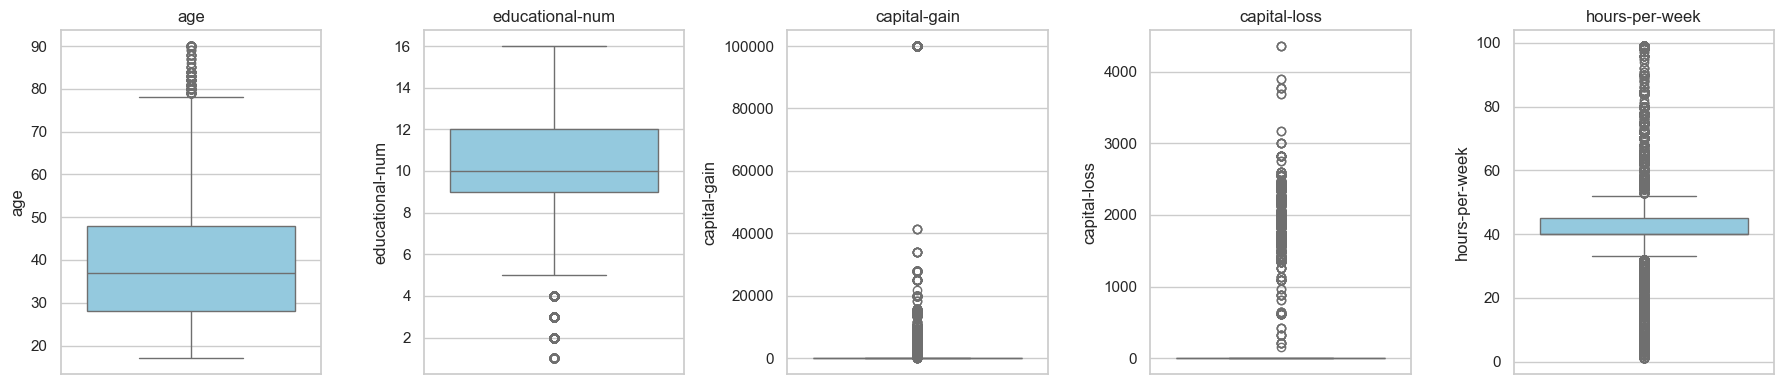

capital-gain == 99999 rows: 244 (a known top-code placeholder)


In [10]:
# 2.8 Outlier inspection with the IQR rule
num_cols = ["age", "educational-num", "capital-gain", "capital-loss", "hours-per-week"]

rows = []
for c in num_cols:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[c] < lo) | (df[c] > hi)).sum()
    rows.append([c, lo, hi, n_out, round(n_out / len(df) * 100, 2)])
display(pd.DataFrame(rows, columns=["feature", "lower_bound", "upper_bound", "n_outliers", "outlier_%"]))

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, c in zip(axes, num_cols):
    sns.boxplot(y=df[c], ax=ax, color="skyblue")
    ax.set_title(c)
plt.tight_layout()
plt.show()

print("capital-gain == 99999 rows:", (df["capital-gain"] == 99999).sum(), "(a known top-code placeholder)")

**Decision on outliers:** we **keep** them. Decision Trees and Random Forests split on thresholds, so they are not sensitive to extreme values. Also, many "outliers" here (high `capital-gain`, long `hours-per-week`) are real and strongly related to high income, so removing them would throw away useful signal.

In [11]:
print("Final cleaned shape:", df.shape)
df_clean = df.copy()
df_clean.head()

Final cleaned shape: (48789, 13)


,age,workclass,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,Private,10,Never-married,Prof-specialty,Own-child,White,Female,0,0,30,United-States,<=50K


## 3. Exploratory Data Analysis and Visualization

### 3.1 Target distribution

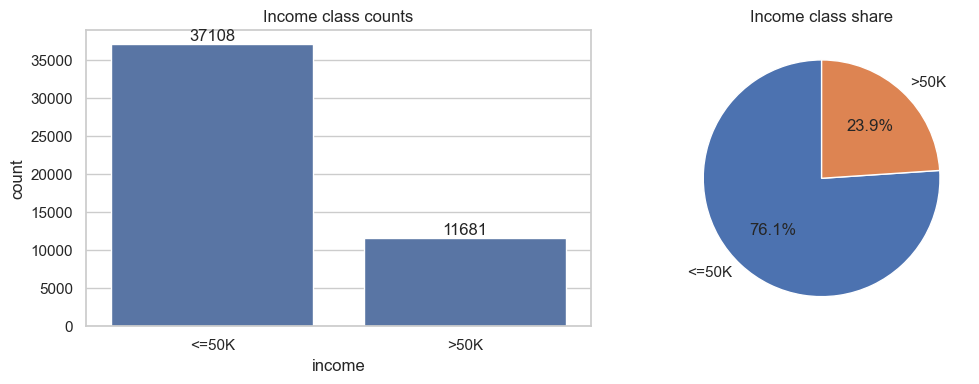

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
order = df["income"].value_counts().index
sns.countplot(x="income", data=df, order=order, ax=axes[0])
axes[0].set_title("Income class counts")
for p in axes[0].patches:
    axes[0].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha="center", va="bottom")
df["income"].value_counts().plot.pie(autopct="%1.1f%%", ax=axes[1], startangle=90)
axes[1].set_ylabel("")
axes[1].set_title("Income class share")
plt.tight_layout(); plt.show()

The classes are **imbalanced** (roughly 76% `<=50K` vs 24% `>50K`). So accuracy alone is misleading; we will also look at precision, recall, F1 and ROC-AUC.

### 3.2 Numerical features

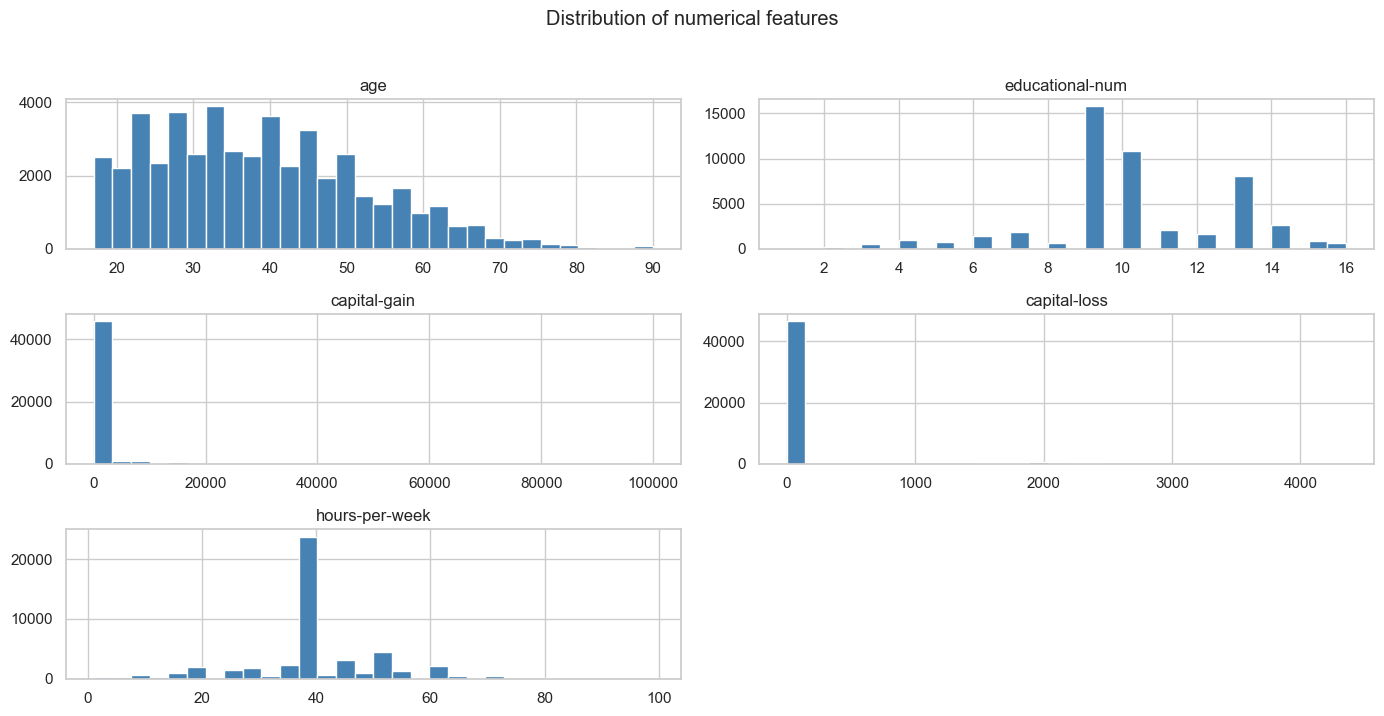

In [13]:
df[num_cols].hist(bins=30, figsize=(14, 7), color="steelblue", edgecolor="white")
plt.suptitle("Distribution of numerical features", y=1.02)
plt.tight_layout(); plt.show()

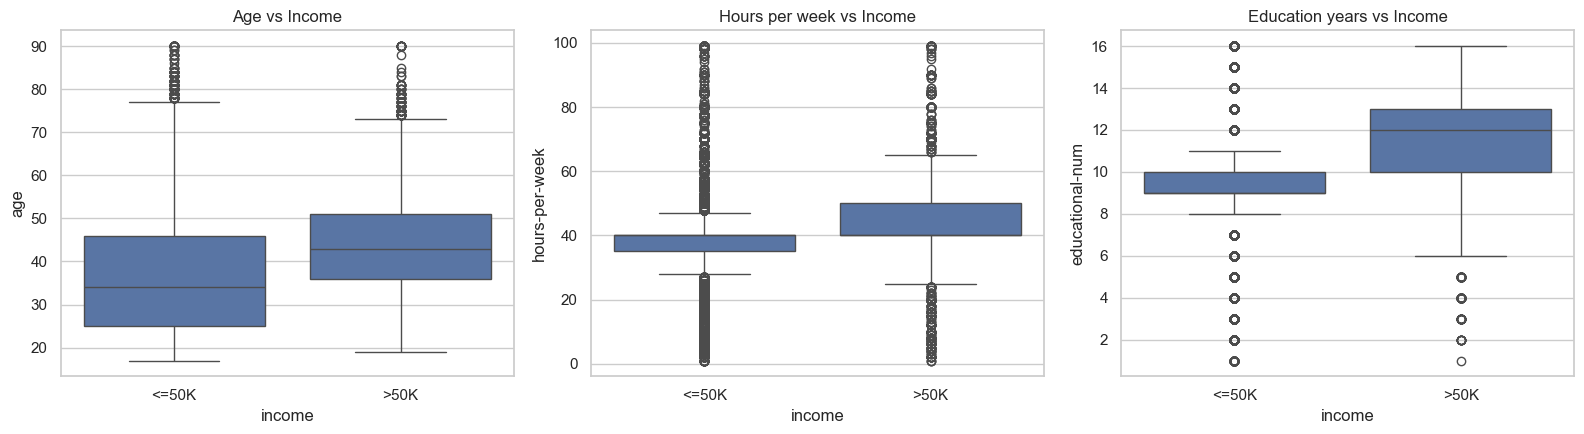

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.boxplot(x="income", y="age", data=df, ax=axes[0])
axes[0].set_title("Age vs Income")
sns.boxplot(x="income", y="hours-per-week", data=df, ax=axes[1])
axes[1].set_title("Hours per week vs Income")
sns.boxplot(x="income", y="educational-num", data=df, ax=axes[2])
axes[2].set_title("Education years vs Income")
plt.tight_layout(); plt.show()

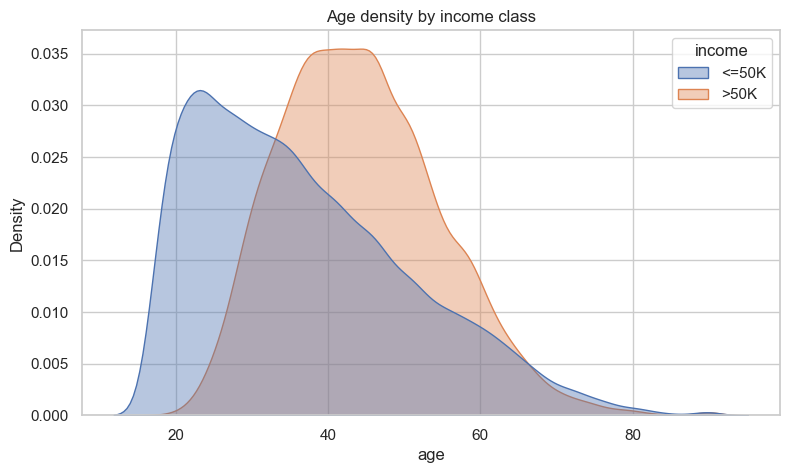

In [15]:
plt.figure(figsize=(9, 5))
sns.kdeplot(data=df, x="age", hue="income", fill=True, common_norm=False, alpha=0.4)
plt.title("Age density by income class")
plt.show()

### 3.3 Categorical features vs income

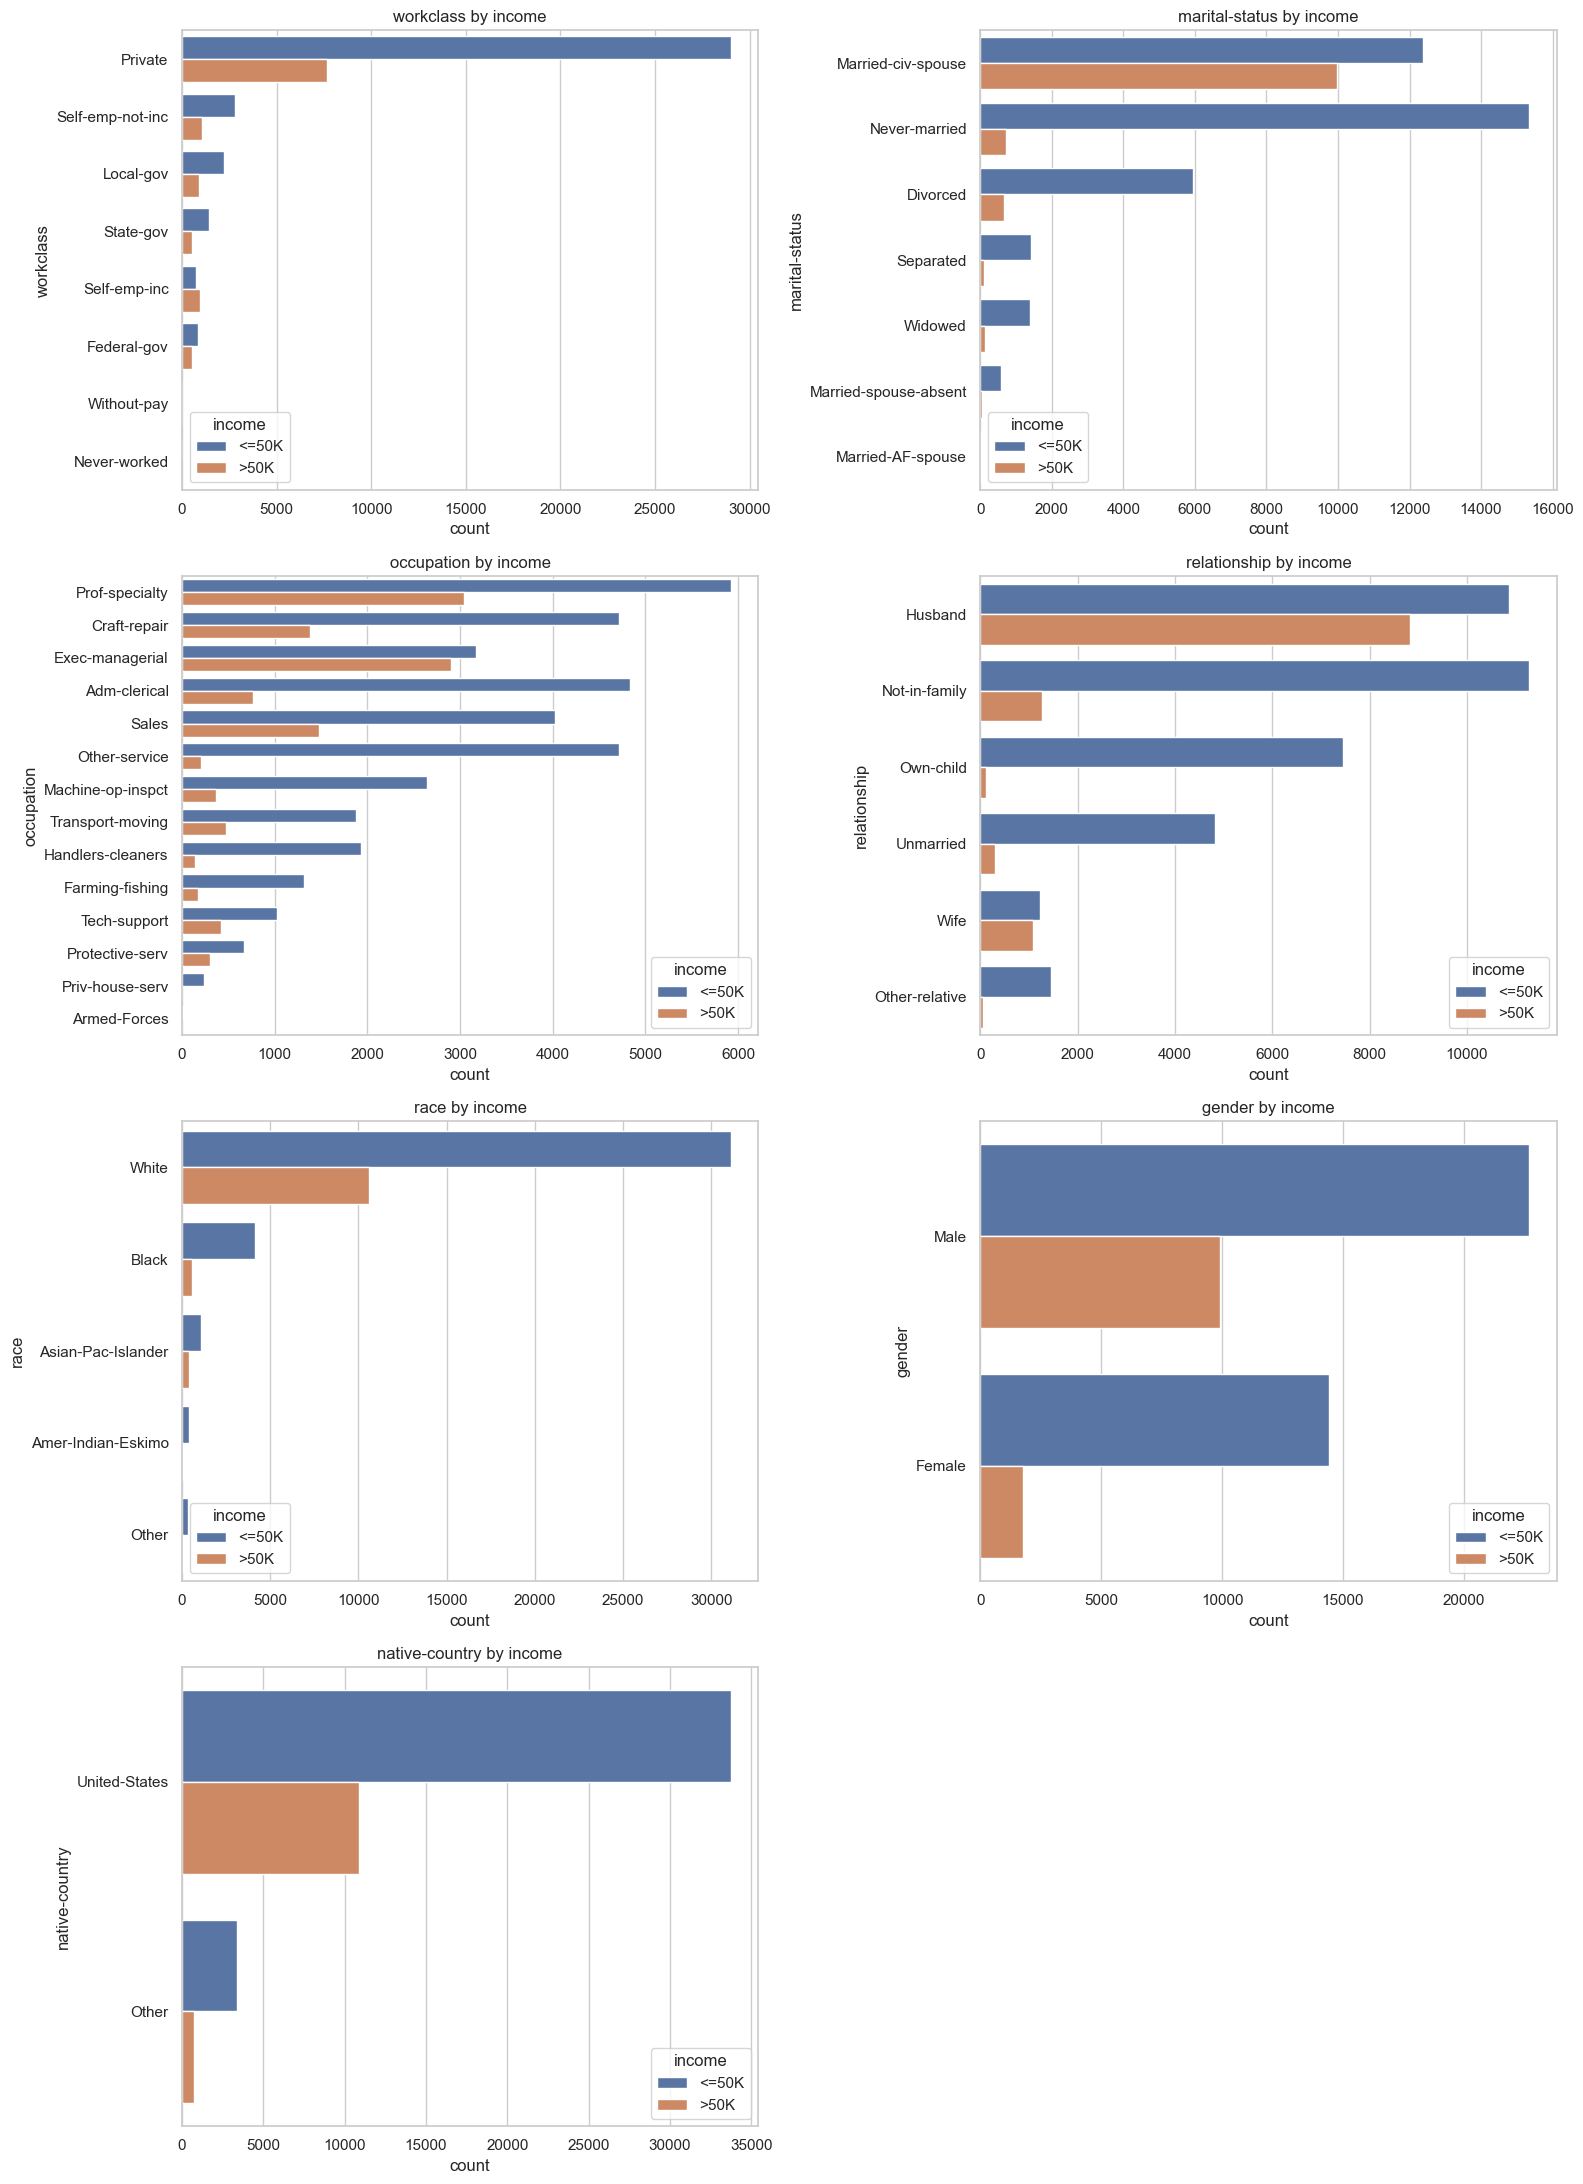

In [16]:
cat_cols = ["workclass", "marital-status", "occupation", "relationship",
            "race", "gender", "native-country"]

fig, axes = plt.subplots(4, 2, figsize=(16, 22))
axes = axes.ravel()
for ax, c in zip(axes, cat_cols):
    order = df[c].value_counts().index
    sns.countplot(y=c, hue="income", data=df, order=order, ax=ax)
    ax.set_title(f"{c} by income")
axes[-1].axis("off")
plt.tight_layout(); plt.show()

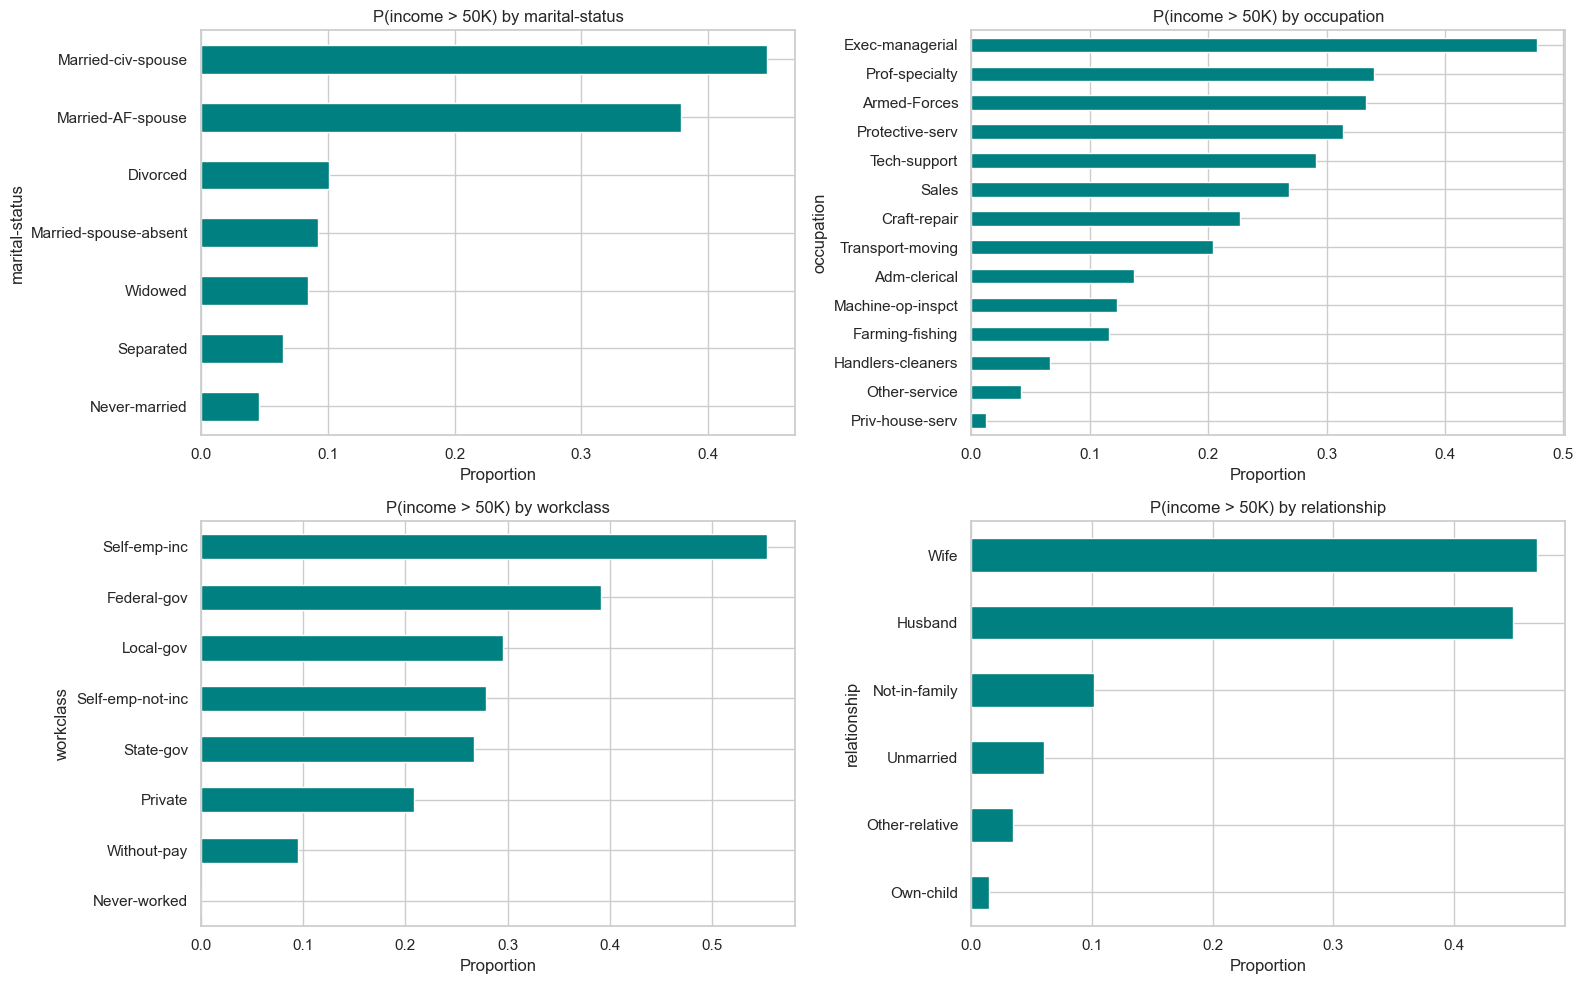

In [17]:
# Share of >50K inside each category (more informative than raw counts)
df["high_income"] = (df["income"] == ">50K").astype(int)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, c in zip(axes.ravel(), ["marital-status", "occupation", "workclass", "relationship"]):
    rate = df.groupby(c)["high_income"].mean().sort_values()
    rate.plot.barh(ax=ax, color="teal")
    ax.set_title(f"P(income > 50K) by {c}")
    ax.set_xlabel("Proportion")
plt.tight_layout(); plt.show()

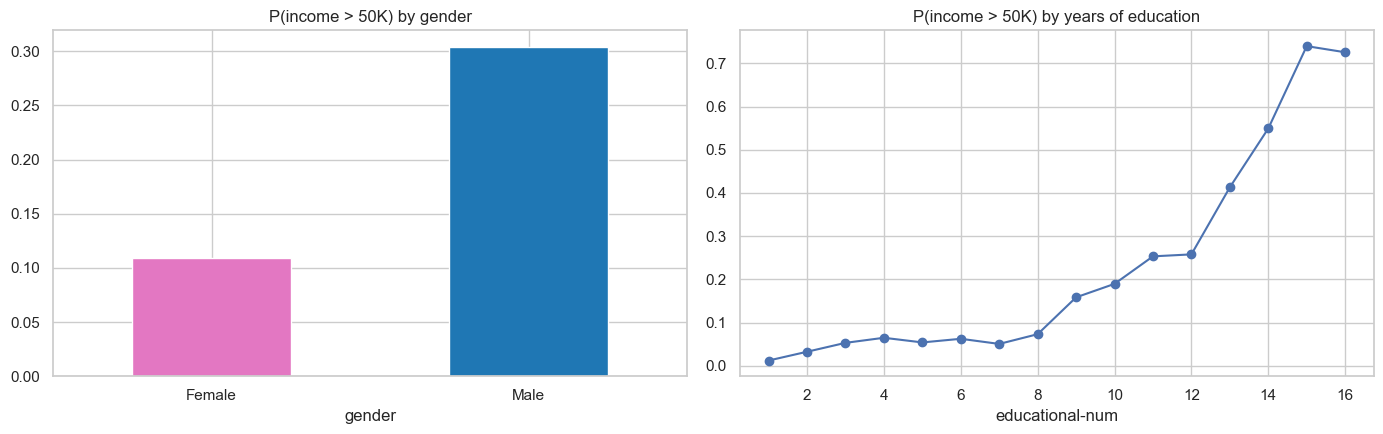

In [18]:
# Gender gap and education effect
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
df.groupby("gender")["high_income"].mean().plot.bar(ax=axes[0], color=["#e377c2", "#1f77b4"], rot=0)
axes[0].set_title("P(income > 50K) by gender")
df.groupby("educational-num")["high_income"].mean().plot(marker="o", ax=axes[1])
axes[1].set_title("P(income > 50K) by years of education")
axes[1].set_xlabel("educational-num")
plt.tight_layout(); plt.show()

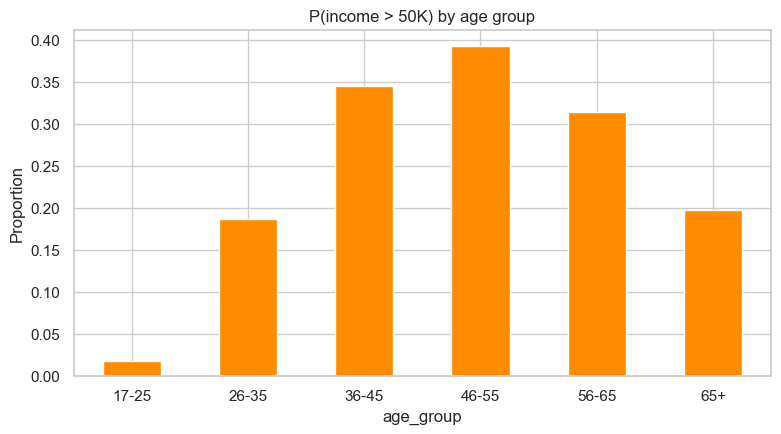

In [19]:
# Age groups and hours worked
df["age_group"] = pd.cut(df["age"], bins=[16, 25, 35, 45, 55, 65, 100],
                         labels=["17-25", "26-35", "36-45", "46-55", "56-65", "65+"])
plt.figure(figsize=(9, 4.5))
df.groupby("age_group")["high_income"].mean().plot.bar(color="darkorange", rot=0)
plt.title("P(income > 50K) by age group")
plt.ylabel("Proportion")
plt.show()

# These helper columns are only for plotting
df = df.drop(columns=["age_group"])

### 3.4 Correlation analysis

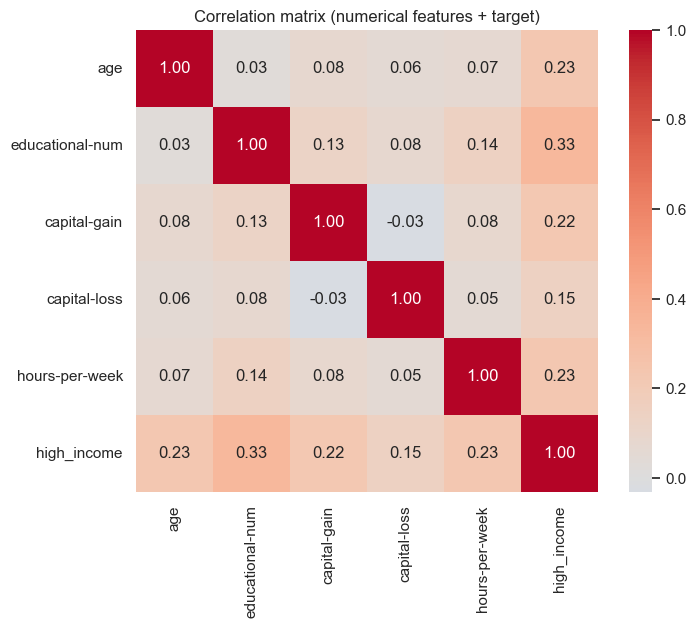

In [20]:
corr = df[num_cols + ["high_income"]].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation matrix (numerical features + target)")
plt.show()

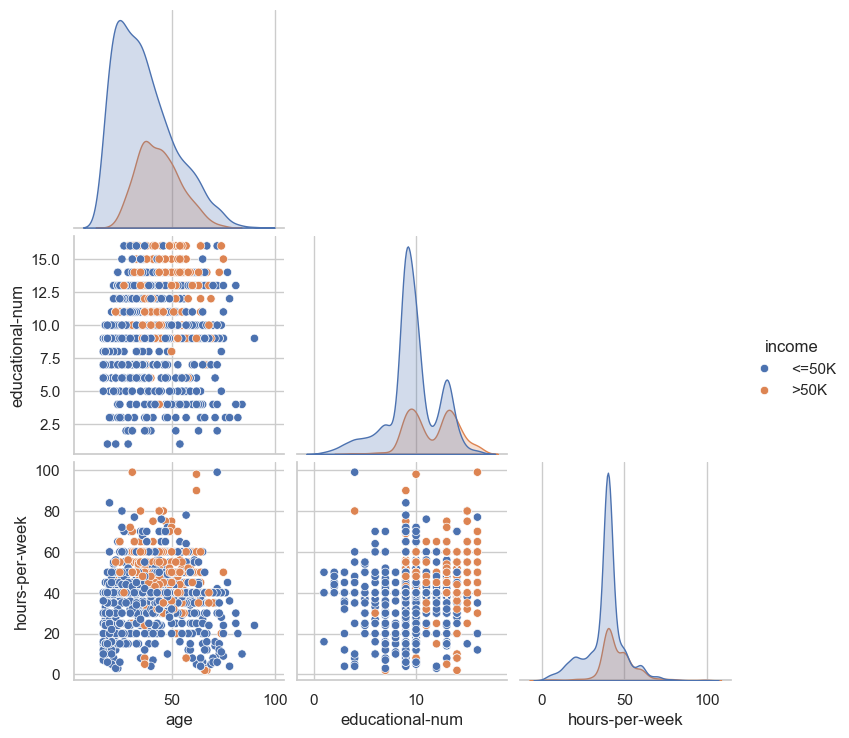

In [21]:
sns.pairplot(df.sample(2000, random_state=RANDOM_STATE),
             vars=["age", "educational-num", "hours-per-week"],
             hue="income", diag_kind="kde", corner=True)
plt.show()

**Main EDA takeaways** (verify against your plots):
- Income is imbalanced toward `<=50K`.
- Higher education, being married (especially `Married-civ-spouse`), professional or managerial occupations, more working hours and mid-career age are all associated with `>50K`.
- `capital-gain` is highly skewed: most people have 0, but non-zero values strongly indicate high income.
- There is a visible gender gap in the share of `>50K`.

## 4. Preprocessing for Modeling

- Encode the target: `>50K` = 1, `<=50K` = 0
- One-hot encode categorical features (`drop_first=True` to avoid redundant columns)
- Stratified 80/20 train/test split, so both sets keep the same class ratio

No scaling is needed: tree-based models are not sensitive to feature scale.

In [22]:
df_model = df.drop(columns=["high_income"])
y = (df_model["income"] == ">50K").astype(int)
X = pd.get_dummies(df_model.drop(columns=["income"]), drop_first=True)

print("Feature matrix shape:", X.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Positive rate train/test:", y_train.mean().round(3), y_test.mean().round(3))

Feature matrix shape: (48789, 42)
Train: (39031, 42)  Test: (9758, 42)
Positive rate train/test: 0.239 0.239


In [23]:
# Helper to evaluate any fitted model in the same way
results = {}

def evaluate(name, model):
    pred_tr = model.predict(X_train)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    results[name] = {
        "Train Acc": accuracy_score(y_train, pred_tr),
        "Test Acc": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    }
    print(f"=== {name} ===")
    print(classification_report(y_test, pred, target_names=["<=50K", ">50K"]))
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["<=50K", ">50K"], cmap="Blues")
    plt.title(f"Confusion matrix: {name}")
    plt.show()

## 5. Decision Tree

### 5.1 Baseline (fully grown tree)
With no depth limit, a tree memorizes the training data. We expect **overfitting**: very high train accuracy but lower test accuracy.

=== Decision Tree (baseline) ===
              precision    recall  f1-score   support

       <=50K       0.88      0.88      0.88      7422
        >50K       0.61      0.61      0.61      2336

    accuracy                           0.81      9758
   macro avg       0.74      0.75      0.75      9758
weighted avg       0.81      0.81      0.81      9758



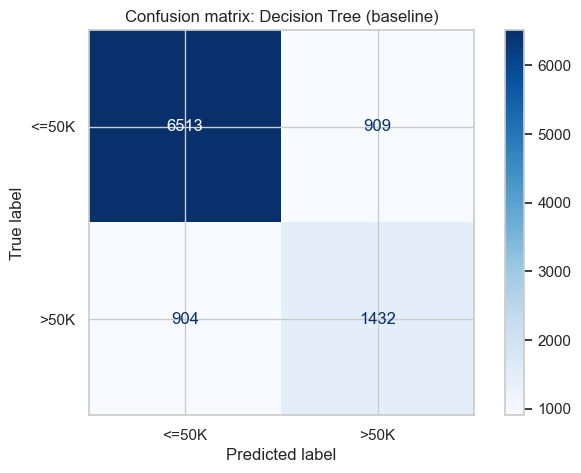

Depth: 49 | Leaves: 6882


In [24]:
dt_base = DecisionTreeClassifier(random_state=RANDOM_STATE)
dt_base.fit(X_train, y_train)
evaluate("Decision Tree (baseline)", dt_base)
print("Depth:", dt_base.get_depth(), "| Leaves:", dt_base.get_n_leaves())

### 5.2 Visualizing the tree (shallow version for readability)

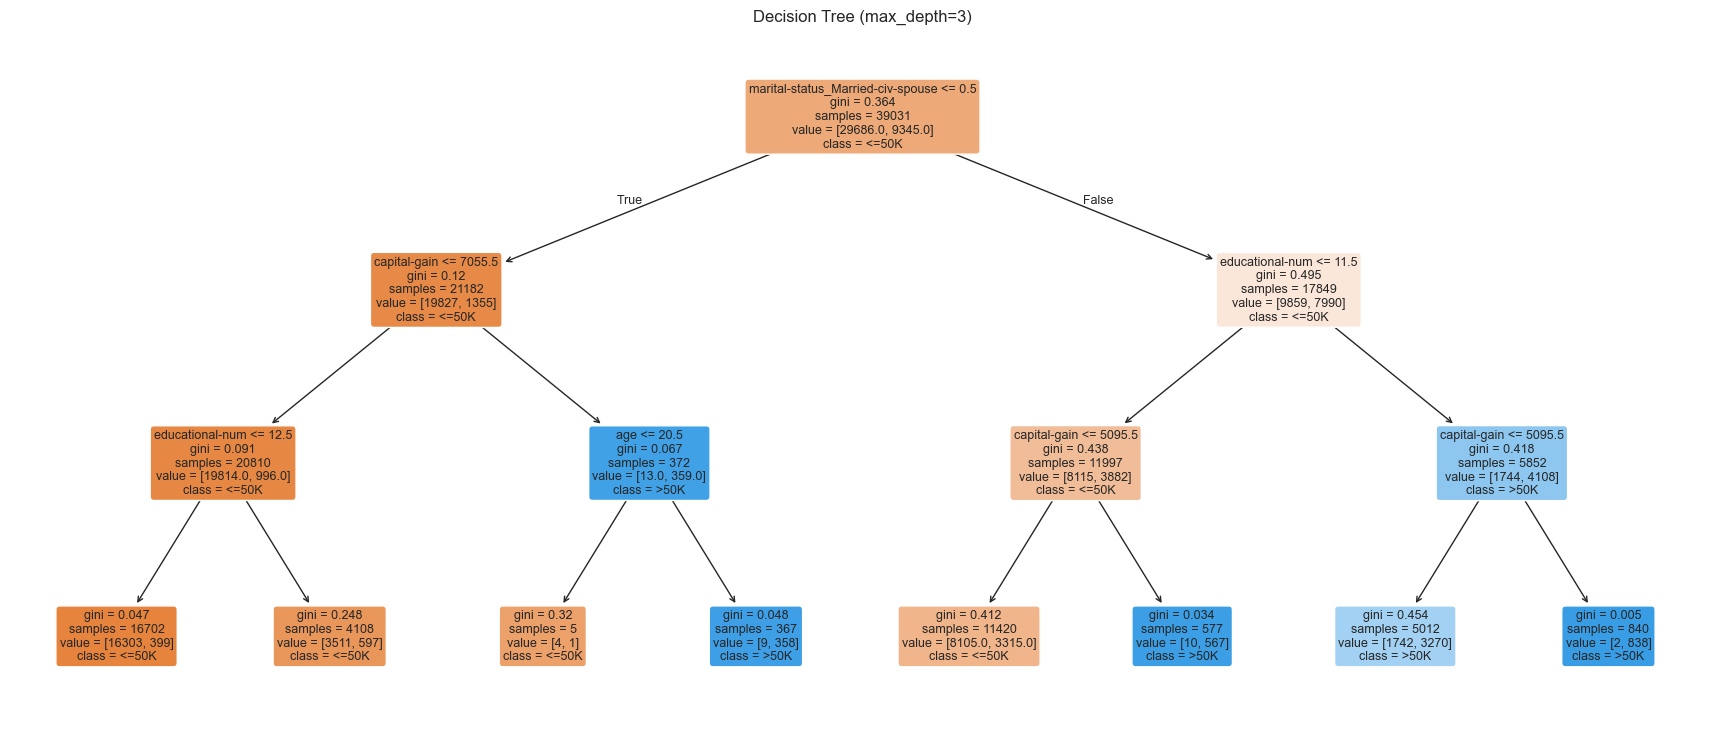

In [25]:
dt_small = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE).fit(X_train, y_train)
plt.figure(figsize=(22, 9))
plot_tree(dt_small, feature_names=X.columns, class_names=["<=50K", ">50K"],
          filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree (max_depth=3)")
plt.show()

### 5.3 Hyperparameter tuning (GridSearchCV)
We tune `max_depth`, `min_samples_leaf` and `criterion` using 5-fold cross-validation, optimizing **F1** because of the class imbalance.

Best params: {'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 50}
Best CV F1: 0.6703
=== Decision Tree (tuned) ===
              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.91      7422
        >50K       0.75      0.61      0.67      2336

    accuracy                           0.86      9758
   macro avg       0.81      0.77      0.79      9758
weighted avg       0.85      0.86      0.85      9758



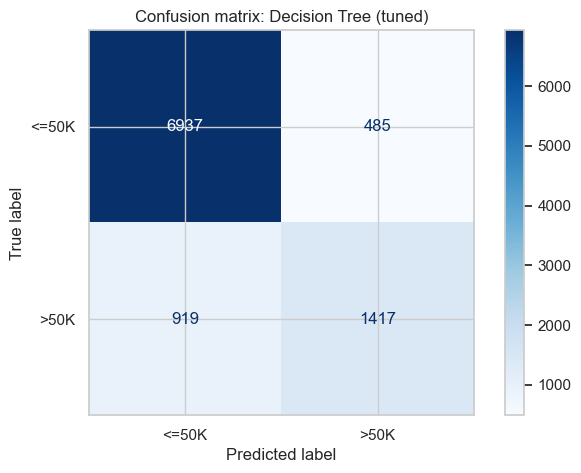

In [26]:
dt_params = {
    "max_depth": [3, 5, 7, 9, 12, None],
    "min_samples_leaf": [1, 5, 10, 20, 50],
    "criterion": ["gini", "entropy"],
}
dt_grid = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE),
                       dt_params, cv=5, scoring="f1", n_jobs=-1)
dt_grid.fit(X_train, y_train)

print("Best params:", dt_grid.best_params_)
print("Best CV F1:", round(dt_grid.best_score_, 4))

dt_best = dt_grid.best_estimator_
evaluate("Decision Tree (tuned)", dt_best)

## 6. Random Forest

### 6.1 Baseline
A Random Forest averages many decorrelated trees (bagging plus random feature subsets), which reduces variance and usually generalizes better than a single tree.

=== Random Forest (baseline) ===
              precision    recall  f1-score   support

       <=50K       0.88      0.91      0.90      7422
        >50K       0.69      0.61      0.65      2336

    accuracy                           0.84      9758
   macro avg       0.79      0.76      0.77      9758
weighted avg       0.84      0.84      0.84      9758



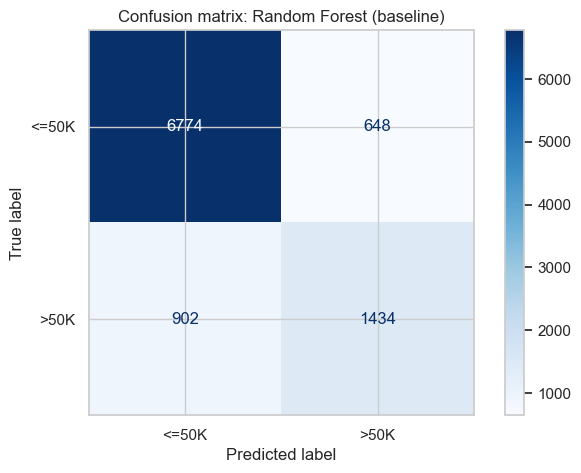

In [27]:
rf_base = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
rf_base.fit(X_train, y_train)
evaluate("Random Forest (baseline)", rf_base)

### 6.2 Hyperparameter tuning (RandomizedSearchCV)

Best params: {'n_estimators': 400, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': None}
Best CV F1: 0.6876
=== Random Forest (tuned) ===
              precision    recall  f1-score   support

       <=50K       0.89      0.94      0.91      7422
        >50K       0.76      0.62      0.68      2336

    accuracy                           0.86      9758
   macro avg       0.82      0.78      0.80      9758
weighted avg       0.86      0.86      0.86      9758



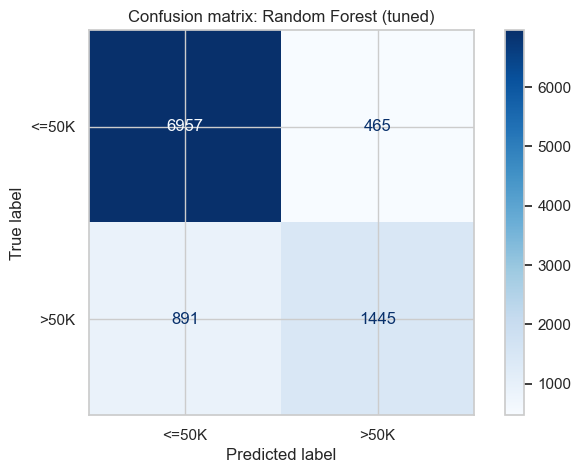

In [28]:
rf_params = {
    "n_estimators": [100, 200, 300, 400],
    "max_depth": [8, 12, 16, 20, None],
    "min_samples_leaf": [1, 2, 5, 10],
    "min_samples_split": [2, 5, 10],
    "max_features": ["sqrt", "log2"],
}
rf_search = RandomizedSearchCV(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
                               rf_params, n_iter=20, cv=3, scoring="f1",
                               random_state=RANDOM_STATE, n_jobs=-1)
rf_search.fit(X_train, y_train)

print("Best params:", rf_search.best_params_)
print("Best CV F1:", round(rf_search.best_score_, 4))

rf_best = rf_search.best_estimator_
evaluate("Random Forest (tuned)", rf_best)

## 7. Model Comparison

,Train Acc,Test Acc,Precision,Recall,F1,ROC-AUC
Random Forest (tuned),0.9053,0.8610,0.7565,0.6186,0.6806,0.9148
Decision Tree (tuned),0.8669,0.8561,0.7450,0.6066,0.6687,0.9020
Random Forest (baseline),0.9733,0.8412,0.6888,0.6139,0.6492,0.8901
Decision Tree (baseline),0.9733,0.8142,0.6117,0.6130,0.6124,0.7750


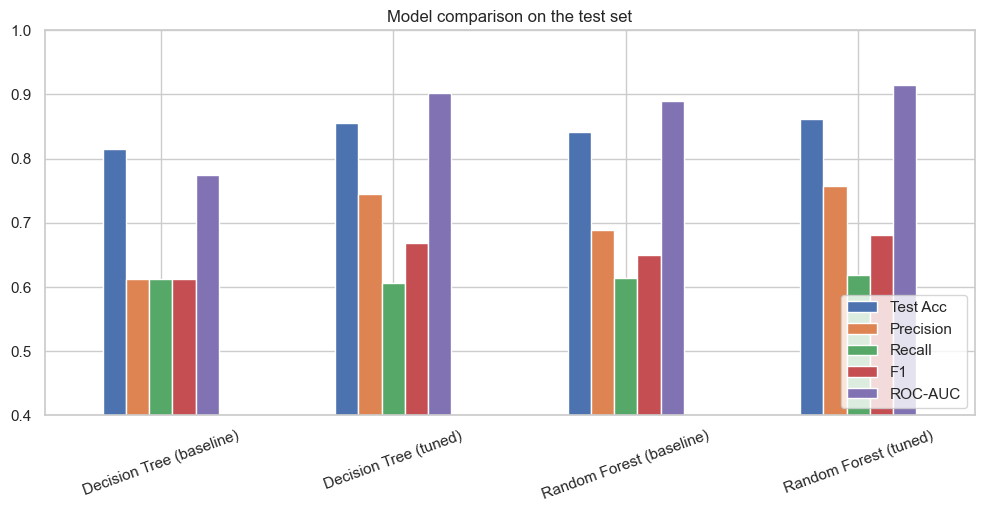

In [29]:
comparison = pd.DataFrame(results).T.round(4)
display(comparison.sort_values("F1", ascending=False))

comparison[["Test Acc", "Precision", "Recall", "F1", "ROC-AUC"]].plot.bar(figsize=(12, 5), rot=20)
plt.title("Model comparison on the test set")
plt.ylim(0.4, 1.0)
plt.legend(loc="lower right")
plt.show()

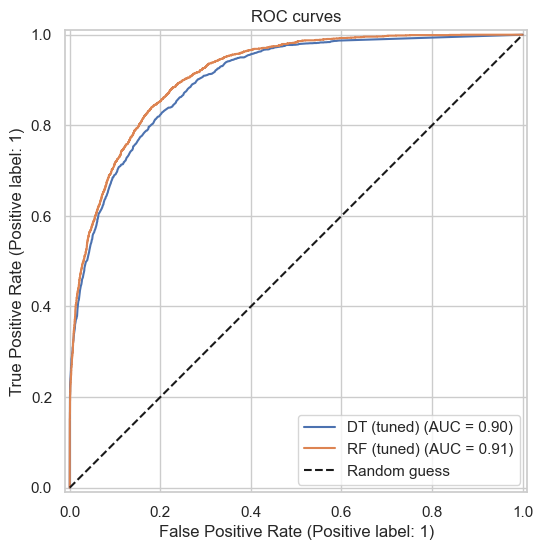

In [30]:
# ROC curves
fig, ax = plt.subplots(figsize=(7, 6))
for name, model in [("DT (tuned)", dt_best), ("RF (tuned)", rf_best)]:
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random guess")
ax.set_title("ROC curves")
ax.legend()
plt.show()

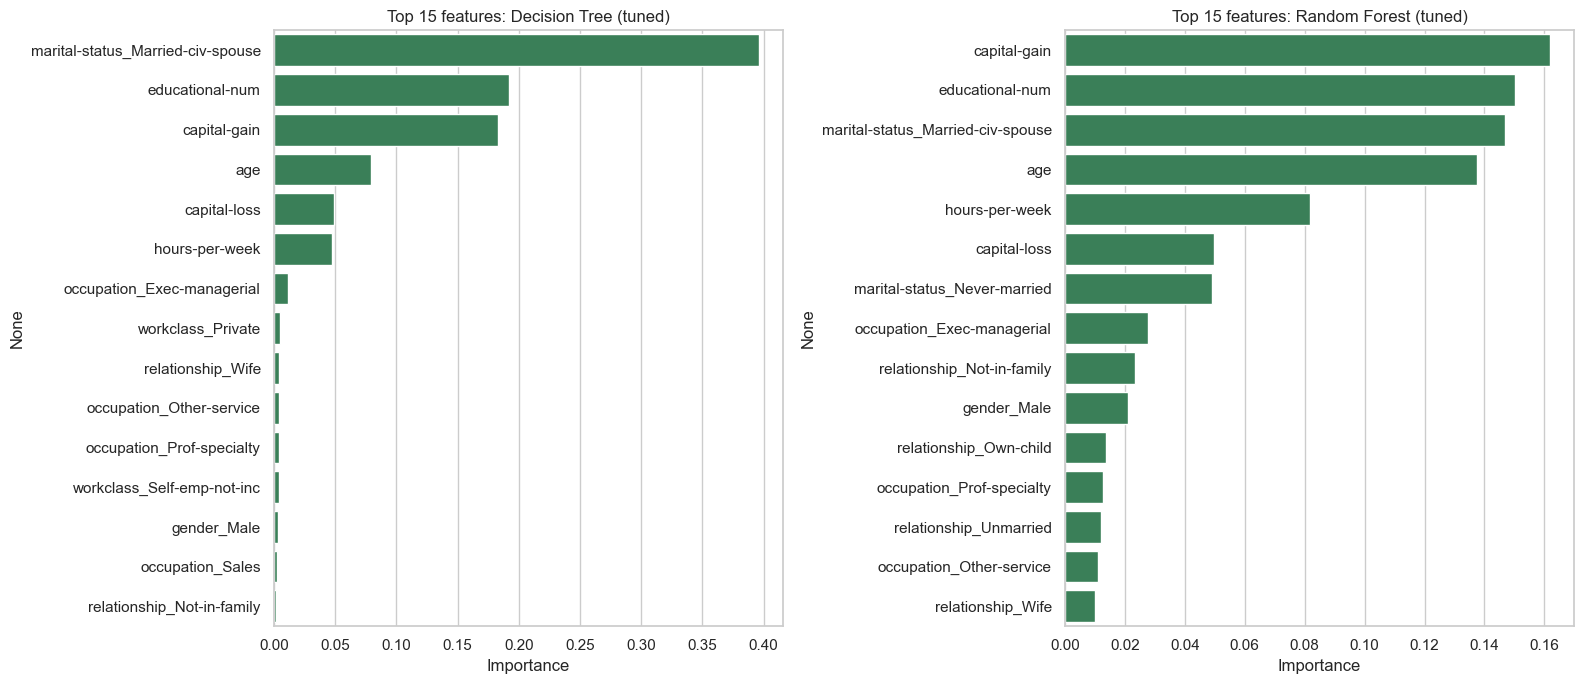

In [31]:
# Feature importance
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, (name, model) in zip(axes, [("Decision Tree (tuned)", dt_best), ("Random Forest (tuned)", rf_best)]):
    imp = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False).head(15)
    sns.barplot(x=imp.values, y=imp.index, ax=ax, color="seagreen")
    ax.set_title(f"Top 15 features: {name}")
    ax.set_xlabel("Importance")
plt.tight_layout(); plt.show()

## 8. Conclusions

- **Cleaning:** the `?` placeholders (in `workclass`, `occupation`, `native-country`) were converted to `NaN` and imputed with the mode; duplicates were removed; `education` and `fnlwgt` were dropped; `native-country` was reduced to two groups.
- **EDA:** the target is imbalanced (about 76/24). Education, marital status, relationship, occupation, age, hours per week and capital gain are the most informative signals.
- **Decision Tree:** the unpruned tree overfits (train accuracy near 100%). Tuning depth and leaf size reduces the gap and improves generalization, and the tree stays easy to interpret.
- **Random Forest:** usually gives the best F1 and ROC-AUC, since averaging many trees reduces variance. The trade-off is lower interpretability and longer training time.
- **Possible improvements:** handle the imbalance (`class_weight="balanced"` or SMOTE), tune the decision threshold, try Gradient Boosting / XGBoost, and check fairness across gender and race.